# Fairness Metrics in the P2P Electricity Market
### Case study: January 15, 2016 · Base structure (4 prosumers, case33bw)

This notebook walks through every fairness metric used in the analysis —
what each one measures, how it behaves on this specific day, and what
the **Price of Optimality** (PoO) and **Price of Fairness** (PoF) tell
us about the tension between efficiency and equity.

All computations use the centralised social-optimum result for Jan 15
and the no-trade baseline, both read from the saved result library.


## 1  Setup

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

# ── project root (adjust if running from a different directory) ───────────────
ROOT = Path('.').resolve()
sys.path.insert(0, str(ROOT))

from scenarios import make_scenario_date
from metrics  import (savings, sw, tw, mm, jains, var_savings,
                      fair_optimal_SW, fair_optimal_MM, poo, pof)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'figure.dpi': 120,
})

DATE      = '2016-01-15'
STRUCTURE = 'base'
RESULT_DIR = ROOT / 'structures' / STRUCTURE / 'results' / DATE
print(f"Loading from: {RESULT_DIR}")


Loading from: /Users/catharinahente/Documents/Github/p2p-energy-trading-illustrative/structures/base/results/2016-01-15


## 2  Load Jan 15 results

In [4]:
# No-trade baseline
nt   = json.loads((RESULT_DIR / 'no_trade.json').read_text())
J_nt = np.array(nt['J_nt'])

# Centralised social-optimum result
raw  = json.loads((RESULT_DIR / 'centralized.json').read_text())
J_so = np.array(raw['costs'])

# Names come from the scenario, not the result file
data_tmp = make_scenario_date(DATE, seed=42, resolution_h=0.5)
names    = data_tmp['prosumer_names']
N        = len(names)
short    = [n.replace('Residential ', 'Res. ').replace('building', 'bldg') for n in names]



Building winter scenario (T=48, dt=0.5h, resolution=30min)...
  Prices 2016: loaded from cache
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
    ⚠ No EV activity detected — using fallback schedule
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=18.2 kW


In [5]:
# Rebuild scenario so fair_optimal_* can solve
data = make_scenario_date(DATE, seed=42, resolution_h=0.5)

# Savings vector
d_so = savings({'costs': J_so}, J_nt)

print("\nSavings d_i = (J_nt - J_so) / |J_nt|:")
for i, (n, di) in enumerate(zip(names, d_so)):
    sign = '+' if di >= 0 else ''
    print(f"  P{i+1} {n}: {sign}{di:.4f}")


Building winter scenario (T=48, dt=0.5h, resolution=30min)...
  Prices 2016: loaded from cache
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
    ⚠ No EV activity detected — using fallback schedule
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=18.2 kW

Savings d_i = (J_nt - J_so) / |J_nt|:
  P1 Residential ++: -0.1532
  P2 Office building: +0.0628
  P3 Residential HP only: +0.1231
  P4 Residential PV only: +0.0527


## 3  The savings vector

$$d_i = \frac{J_i^{\text{nt}} - J_i(x^{\text{SO}})}{|J_i^{\text{nt}}|}$$

$d_i > 0$: prosumer $i$ is better off trading than operating alone.  
$d_i < 0$: prosumer $i$ is **worse off** — it is cross-subsidising others.  
$d_i = 0$: trading makes no difference.

Dividing by $|J_i^{\text{nt}}|$ (not $J_i^{\text{nt}}$) makes the fraction
correct even when a prosumer has a negative no-trade cost (net exporter).  
The normalisation puts prosumers of very different sizes on a comparable scale
(Cardinal Unit Comparability — Hall et al. 2025, §III-B; Behrunani et al. 2021).


/var/folders/ws/2f14f99n4gz0_l440g5w34j00000gn/T/ipykernel_35594/32277802.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'P{i+1}  {short[i]}' for i in range(N)], fontsize=9)


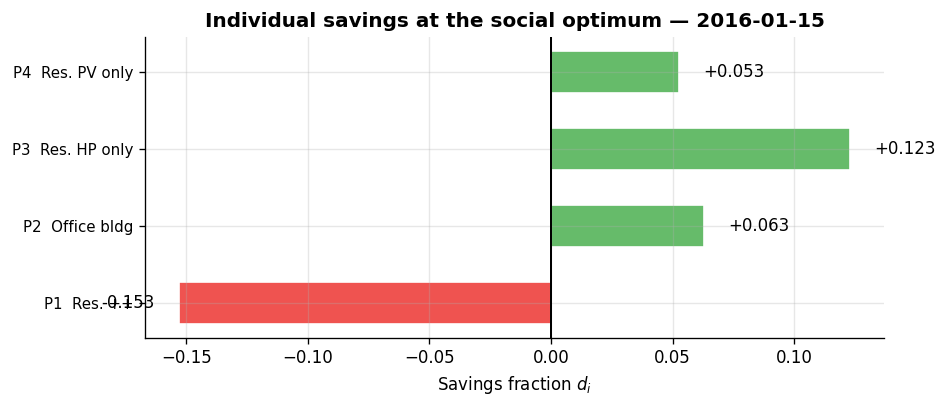


P1 is worse off by 15% relative to its no-trade baseline.
The social optimum uses P1's flexibility to benefit the community.


In [6]:
COLORS = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63']   # P1 P2 P3 P4
BAR_C  = ['#EF5350' if d < 0 else '#66BB6A' for d in d_so]

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh([f'P{i+1}' for i in range(N)], d_so,
               color=BAR_C, edgecolor='white', height=0.55)

ax.axvline(0, color='black', linewidth=1.2)
ax.set_xlabel('Savings fraction $d_i$')
ax.set_title(f'Individual savings at the social optimum — {DATE}', fontweight='bold')

for bar, d in zip(bars, d_so):
    ha  = 'left' if d >= 0 else 'right'
    off = 0.01 if d >= 0 else -0.01
    ax.text(d + off, bar.get_y() + bar.get_height()/2,
            f'{d:+.3f}', va='center', ha=ha, fontsize=10)

ax.set_yticklabels([f'P{i+1}  {short[i]}' for i in range(N)], fontsize=9)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fairness_savings.pdf', bbox_inches='tight')
plt.show()
print("\nP1 is worse off by {:.0f}% relative to its no-trade baseline.".format(
    abs(d_so[0]) * 100))
print("The social optimum uses P1's flexibility to benefit the community.")


## 4  Fairness metrics at the social optimum

All metrics are computed on $d = (d_1, \ldots, d_N)$ unless stated otherwise.


In [7]:
TW_val  = tw(J_nt, J_so)
SW_val  = sw(d_so)
MM_val  = mm(d_so)
JI_val  = jains(d_so)
Var_val = var_savings(d_so)

metrics_so = {
    'TW  (Total Welfare)':       TW_val,
    'SW  (Social Welfare Σdᵢ)':  SW_val,
    'MM  (Maximin  min dᵢ)':     MM_val,
    "JI  (Jain's Index)":        JI_val,
    'Var (Variance of d)':       Var_val,
}

print("Fairness metrics at the social optimum:")
for k, v in metrics_so.items():
    print(f"  {k:35s} {v:+.4f}")


Fairness metrics at the social optimum:
  TW  (Total Welfare)                 +0.0571
  SW  (Social Welfare Σdᵢ)            +0.0854
  MM  (Maximin  min dᵢ)               -0.1532
  JI  (Jain's Index)                  +0.0402
  Var (Variance of d)                 +0.0109


### What each metric means

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **TW** | $(\sum J^{nt} - \sum J) / \sum J^{nt}$ | Community-level efficiency gain from trading. Always ≥ 0 at the SO since the SO minimises total cost. |
| **SW** | $\sum_i d_i$ | Sum of individual savings. Negative here because P1's large loss outweighs others' gains. |
| **MM** | $\min_i d_i$ | Worst-off prosumer's saving. Rawlsian fairness: the market is as fair as its least-favoured participant. |
| **JI** | $(\sum d_i)^2 / (N \sum d_i^2)$ | Jain's index ∈ [0,1] normally; can fall below 1/N when savings are negative. Higher = more equal. |
| **Var** | $(1/N)\sum(d_i - \bar{d})^2$ | Spread of savings. Lower = more equal. |

**TW** is applied to raw costs (EUR); all others to the normalised savings vector $d$.


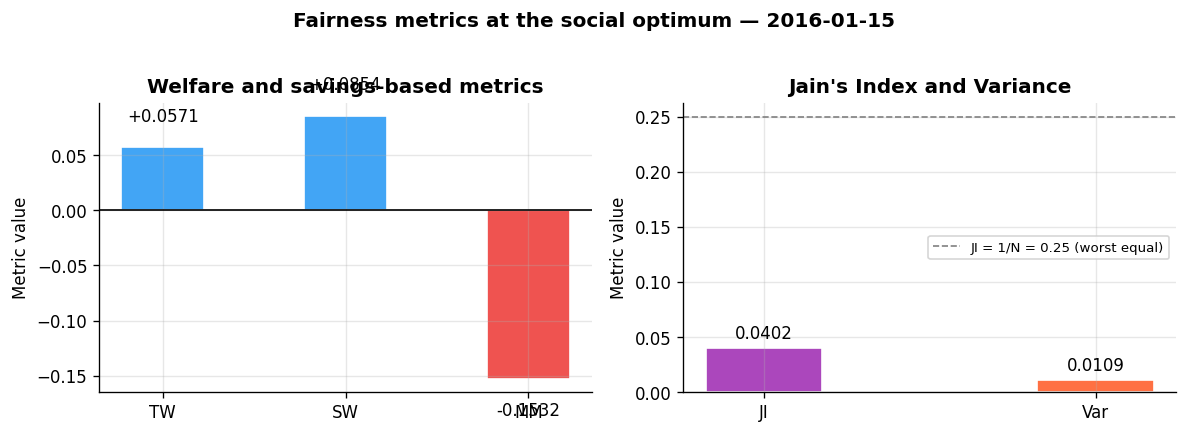

In [8]:
# Visual comparison of SW, MM, JI (Var on secondary axis)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# Left: SW and MM (both on d-scale, can be negative)
metric_names_left = ['TW', 'SW', 'MM']
metric_vals_left  = [TW_val, SW_val, MM_val]
bar_colors_left   = ['#42A5F5' if v >= 0 else '#EF5350' for v in metric_vals_left]
ax = axes[0]
ax.bar(metric_names_left, metric_vals_left, color=bar_colors_left,
       edgecolor='white', width=0.45)
ax.axhline(0, color='black', linewidth=1)
for xi, (name, val) in enumerate(zip(metric_names_left, metric_vals_left)):
    va  = 'bottom' if val >= 0 else 'top'
    off = 0.02 if val >= 0 else -0.02
    ax.text(xi, val + off, f'{val:+.4f}', ha='center', va=va, fontsize=10)
ax.set_title('Welfare and savings-based metrics', fontweight='bold')
ax.set_ylabel('Metric value')

# Right: JI and Var
ax2 = axes[1]
ax2.bar(['JI', 'Var'], [JI_val, Var_val], color=['#AB47BC', '#FF7043'],
        edgecolor='white', width=0.35)
for xi, val in enumerate([JI_val, Var_val]):
    ax2.text(xi, val + 0.005, f'{val:.4f}', ha='center', va='bottom', fontsize=10)
ax2.axhline(1/N, color='grey', linestyle='--', linewidth=1,
            label=f'JI = 1/N = {1/N:.2f} (worst equal)')
ax2.legend(fontsize=8)
ax2.set_title("Jain's Index and Variance", fontweight='bold')
ax2.set_ylabel('Metric value')

plt.suptitle(f'Fairness metrics at the social optimum — {DATE}',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fairness_metrics_so.pdf', bbox_inches='tight')
plt.show()


## 5  Fair-optimal allocations

The social optimum minimises $\sum J_i$ — total cost.  
A *fairness-optimal* allocation instead maximises a fairness metric:

- **SW-fair**: $\min \sum J_i / |J_i^{nt}|$ — maximises $\sum d_i$
- **MM-fair**: $\max\; \tau$ s.t. $d_i \geq \tau\;\forall i$ — maximises the worst-off prosumer's saving

These are solved with Gurobi and are the denominators of PoO.


In [9]:
print("Solving SW-fair allocation ...")
r_sw   = fair_optimal_SW(data, J_nt)
d_sw   = savings(r_sw, J_nt)

print("Solving MM-fair allocation ...")
r_mm   = fair_optimal_MM(data, J_nt)
d_mm   = savings(r_mm, J_nt)

print("\nSavings comparison:")
header = f"{'':25s}  {'SO':>8}  {'SW-fair':>8}  {'MM-fair':>8}"
print(header)
print('─' * len(header))
for i in range(N):
    print(f"  P{i+1} {short[i]:20s}  {d_so[i]:+8.4f}  {d_sw[i]:+8.4f}  {d_mm[i]:+8.4f}")
print('─' * len(header))
print(f"  {'SW = Σdᵢ':25s}  {sw(d_so):+8.4f}  {sw(d_sw):+8.4f}  {sw(d_mm):+8.4f}")
print(f"  {'MM = min dᵢ':25s}  {mm(d_so):+8.4f}  {mm(d_sw):+8.4f}  {mm(d_mm):+8.4f}")
print(f"  {'TW (raw costs)':25s}  {tw(J_nt,J_so):+8.4f}  {tw(J_nt,np.array(r_sw['costs'])):+8.4f}  {tw(J_nt,np.array(r_mm['costs'])):+8.4f}")


Solving SW-fair allocation ...
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2806500
Academic license 2806500 - for non-commercial use only - registered to ch___@ethz.ch
Solving MM-fair allocation ...

Savings comparison:
                                 SO   SW-fair   MM-fair
───────────────────────────────────────────────────────
  P1 Res. ++                -0.1532   +0.3219   +0.0567
  P2 Office bldg            +0.0628   +0.0020   +0.0567
  P3 Res. HP only           +0.1231   +0.3104   +0.0567
  P4 Res. PV only           +0.0527   +0.2607   +0.0567
───────────────────────────────────────────────────────
  SW = Σdᵢ                    +0.0854   +0.8950   +0.2269
  MM = min dᵢ                 -0.1532   +0.0020   +0.0567
  TW (raw costs)              +0.0571   +0.0516   +0.0567


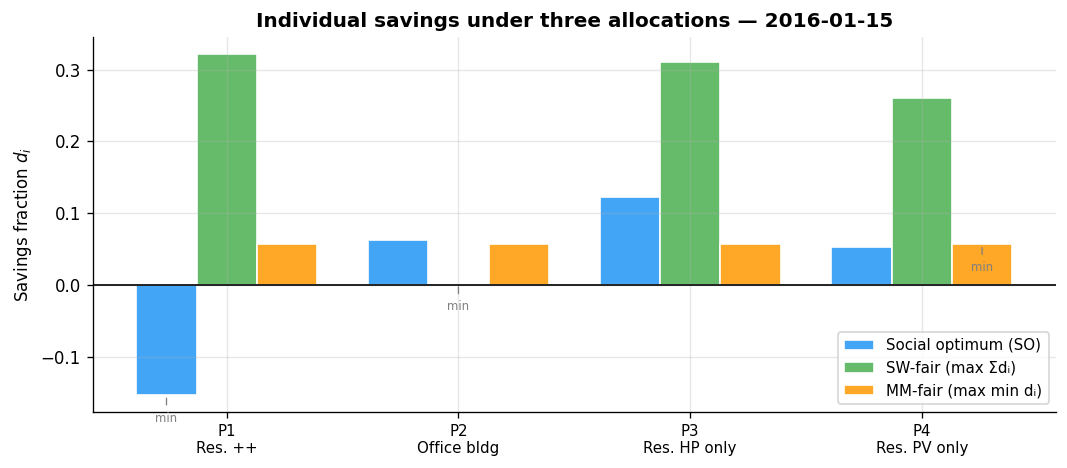

In [11]:
# Grouped bar chart: SO vs SW-fair vs MM-fair
x     = np.arange(N)
width = 0.26
fig, ax = plt.subplots(figsize=(9, 4))

b1 = ax.bar(x - width, d_so, width, label='Social optimum (SO)',  color='#42A5F5', edgecolor='white')
b2 = ax.bar(x,          d_sw, width, label='SW-fair (max Σdᵢ)',    color='#66BB6A', edgecolor='white')
b3 = ax.bar(x + width,  d_mm, width, label='MM-fair (max min dᵢ)', color='#FFA726', edgecolor='white')

ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels([f'P{i+1}\n{short[i]}' for i in range(N)], fontsize=9)
ax.set_ylabel('Savings fraction $d_i$')
ax.set_title(f'Individual savings under three allocations — {DATE}', fontweight='bold')
ax.legend(fontsize=9)

# Annotate min (MM) for each allocation
for bars, d_vec in [(b1, d_so), (b2, d_sw), (b3, d_mm)]:
    mm_idx = int(np.argmin(d_vec))
    bar    = bars[mm_idx]
    y      = bar.get_height() if bar.get_height() >= 0 else bar.get_height()
    ax.annotate('min', xy=(bar.get_x() + bar.get_width()/2, y),
                xytext=(0, -16), textcoords='offset points',
                ha='center', fontsize=7, color='grey',
                arrowprops=dict(arrowstyle='-', color='grey', lw=0.8))

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fairness_allocations.pdf', bbox_inches='tight')
plt.show()


## 6  Price of Optimality and Price of Fairness

$$\text{PoO}_W = 1 - \frac{W(d^{SO})}{W(d^{\text{fair}})}
\qquad
\text{PoF} = 1 - \frac{\text{TW}(x^{\text{fair}})}{\text{TW}(x^{SO})}$$

**PoO** — how much fairness is *lost* by clearing at the social optimum instead of the fairness-optimal point.  
PoO = 0 means the social optimum is already fair. PoO > 1 means the SO actually goes in the wrong direction (possible when the metric is negative at the SO).

**PoF** — how much efficiency is *sacrificed* by moving to the fair allocation.  
PoF = 0 means the fair allocation is just as efficient. PoF > 0 means fairness comes at a cost.

Reference: Bertsimas et al. (2011) · Student proposal eqs (4) and (5).


In [12]:
poo_sw = poo(sw, d_so, d_sw)
poo_mm = poo(mm, d_so, d_mm)
pof_sw = pof({'costs': J_so}, r_sw, J_nt)
pof_mm = pof({'costs': J_so}, r_mm, J_nt)

print(f"PoO_SW = {poo_sw:.4f}")
print(f"PoO_MM = {poo_mm:.4f}")
print(f"PoF_SW = {pof_sw:.4f}")
print(f"PoF_MM = {pof_mm:.4f}")


PoO_SW = 0.9046
PoO_MM = 3.7020
PoF_SW = 0.0966
PoF_MM = 0.0076


/var/folders/ws/2f14f99n4gz0_l440g5w34j00000gn/T/ipykernel_35594/2761994458.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=15, ha='right', fontsize=8)


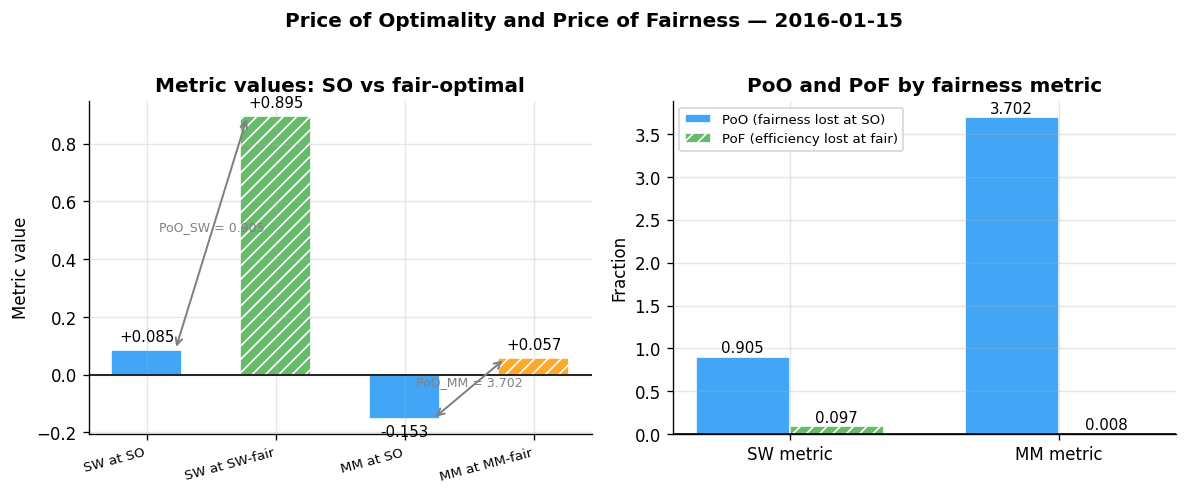

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ── Left: metric values at SO and fair-optimal ────────────────────────────────
ax = axes[0]
labels   = ['SW at SO', 'SW at SW-fair', 'MM at SO', 'MM at MM-fair']
vals     = [sw(d_so), sw(d_sw), mm(d_so), mm(d_mm)]
colors   = ['#42A5F5', '#66BB6A', '#42A5F5', '#FFA726']
hatches  = ['', '///', '', '///']
bars = ax.bar(labels, vals, color=colors, edgecolor='white', width=0.55)
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)
ax.axhline(0, color='black', linewidth=1)
for bar, val in zip(bars, vals):
    va  = 'bottom' if val >= 0 else 'top'
    off = 0.02 if val >= 0 else -0.02
    ax.text(bar.get_x() + bar.get_width()/2, val + off, f'{val:+.3f}',
            ha='center', va=va, fontsize=9)
ax.set_xticklabels(labels, rotation=15, ha='right', fontsize=8)
ax.set_ylabel('Metric value')
ax.set_title('Metric values: SO vs fair-optimal', fontweight='bold')

# Annotate PoO arrows
for (x0, x1, y0, y1, label) in [
    (0, 1, sw(d_so), sw(d_sw), f'PoO_SW = {poo_sw:.3f}'),
    (2, 3, mm(d_so), mm(d_mm), f'PoO_MM = {poo_mm:.3f}'),
]:
    xm = (x0 + x1) / 2
    ax.annotate('', xy=(x1 - 0.22, y1), xytext=(x0 + 0.22, y0),
                arrowprops=dict(arrowstyle='<->', color='grey', lw=1.2))
    ax.text(xm, (y0 + y1)/2, label, ha='center', va='bottom', fontsize=7.5, color='grey')

# ── Right: PoO and PoF ────────────────────────────────────────────────────────
ax2 = axes[1]
poo_vals = [poo_sw, poo_mm]
pof_vals = [pof_sw, pof_mm]
x2 = np.array([0, 1])
w2 = 0.35
ax2.bar(x2 - w2/2, poo_vals, w2, label='PoO (fairness lost at SO)',
        color=['#42A5F5', '#42A5F5'], edgecolor='white', hatch='')
ax2.bar(x2 + w2/2, pof_vals, w2, label='PoF (efficiency lost at fair)',
        color=['#66BB6A', '#FFA726'], edgecolor='white', hatch='///')
ax2.axhline(0, color='black', linewidth=1)
ax2.set_xticks(x2)
ax2.set_xticklabels(['SW metric', 'MM metric'], fontsize=10)
ax2.set_ylabel('Fraction')
ax2.set_title('PoO and PoF by fairness metric', fontweight='bold')
ax2.legend(fontsize=8)

for bar_group in [(x2 - w2/2, poo_vals), (x2 + w2/2, pof_vals)]:
    for xi, val in zip(bar_group[0], bar_group[1]):
        va  = 'bottom' if val >= 0 else 'top'
        off = 0.01 if val >= 0 else -0.01
        ax2.text(xi, val + off, f'{val:.3f}', ha='center', va=va, fontsize=9)

plt.suptitle(f'Price of Optimality and Price of Fairness — {DATE}',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fairness_poo_pof.pdf', bbox_inches='tight')
plt.show()


## 7  Summary table

In [14]:
J_sw = np.array(r_sw['costs'])
J_mm = np.array(r_mm['costs'])

summary = pd.DataFrame({
    'J_nt (EUR)':      J_nt,
    'J_SO (EUR)':      J_so,
    'J_SW-fair (EUR)': J_sw,
    'J_MM-fair (EUR)': J_mm,
    'd_SO':            d_so,
    'd_SW-fair':       d_sw,
    'd_MM-fair':       d_mm,
}, index=[f'P{i+1} {short[i]}' for i in range(N)])

totals = summary.copy()
totals.loc['— Metric values —'] = [np.nan]*7
totals.loc['TW']  = [np.nan, tw(J_nt,J_so),  tw(J_nt,J_sw),  tw(J_nt,J_mm),  np.nan, np.nan, np.nan]
totals.loc['SW']  = [np.nan, np.nan, np.nan, np.nan, sw(d_so), sw(d_sw), sw(d_mm)]
totals.loc['MM']  = [np.nan, np.nan, np.nan, np.nan, mm(d_so), mm(d_sw), mm(d_mm)]
totals.loc['JI']  = [np.nan, np.nan, np.nan, np.nan, jains(d_so), jains(d_sw), jains(d_mm)]
totals.loc['Var'] = [np.nan, np.nan, np.nan, np.nan, var_savings(d_so), var_savings(d_sw), var_savings(d_mm)]
totals.loc['— PoO / PoF —'] = [np.nan]*7
totals.loc['PoO_SW'] = [np.nan]*6 + [poo_sw]
totals.loc['PoO_MM'] = [np.nan]*6 + [poo_mm]
totals.loc['PoF_SW'] = [np.nan]*6 + [pof_sw]
totals.loc['PoF_MM'] = [np.nan]*6 + [pof_mm]

pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 10)
pd.set_option('display.width', 120)
print(totals.to_string(na_rep=''))


                   J_nt (EUR)  J_SO (EUR)  J_SW-fair (EUR)  J_MM-fair (EUR)    d_SO  d_SW-fair  d_MM-fair
P1 Res. ++             2.4082      2.7771           1.6330           2.2716 -0.1532     0.3219     0.0567
P2 Office bldg        64.8885     60.8133          64.7579          61.2092  0.0628     0.0020     0.0567
P3 Res. HP only        2.7061      2.3730           1.8662           2.5526  0.1231     0.3104     0.0567
P4 Res. PV only        8.9328      8.4621           6.6041           8.4263  0.0527     0.2607     0.0567
— Metric values —                                                                                        
TW                                 0.0571           0.0516           0.0567                              
SW                                                                           0.0854     0.8950     0.2269
MM                                                                          -0.1532     0.0020     0.0567
JI                                            

## Key takeaways for Jan 15, 2016

1. **P1 (Residential ++) has d₁ ≈ −1.13** — it pays more than twice its no-trade cost 
   when participating in the market.  The social optimum dispatches P1's EV (V2G) and 
   BESS as community resources to supply P2 (Office, very high demand), but the P2P 
   price does not fully compensate P1 for its cycling costs.

2. **TW is small but positive (≈ 1.6%)** — the community as a whole benefits slightly, 
   but the gain is highly unevenly distributed.

3. **SW < 0 and MM ≈ −1.13** — by either utilitarian or Rawlsian fairness, the social 
   optimum is *unfair*: the sum of savings is negative, and the worst-off participant 
   has a deeply negative saving.

4. **PoO_MM is very large** — the social optimum is far from maximin-fair.  
   The MM-fair allocation raises the minimum saving to ≈ 0, but achieves this at the 
   cost of TW (PoF_MM ≈ 0.09, meaning 9% efficiency loss).

5. **PoF_SW is large (≈ 0.71)** — maximising the sum of savings requires sacrificing 
   71% of total welfare efficiency.  This reflects the deep conflict between 
   utilitarian fairness and economic efficiency on this day.
